This notebook: 
1) validates the function of the Heston model, its pricing and its calibration on simulated data with and without noise
2) Investigates the Fisher information matrix on the simulated market data
3) Investigates the Fisher information as a function of the market data on the strike-maturity surface
4) A first look into the selection of market data on the strike-maturity surface based on the Fisher information through D-optimality criterion (04_calibration_selection.ipynb provides a full run-through of a simulated process)

In [53]:
import numpy as np
import matplotlib.pyplot as plt

from pricing.heston_cf import price_heston_call
from calibration.heston_calib import calibrate_heston
from calibration.fisher import price_sensitivity, scale_fisher_matrix
from calibration.selection import greedy_d_optimal_selection


In [52]:
import calibration.fisher
import importlib
importlib.reload(calibration.fisher)

<module 'calibration.fisher' from 'C:\\Users\\xprp2\\Documents\\python\\derivatives-research\\src\\calibration\\fisher.py'>

In [54]:
# Simulate true parameters of Heston model
true_param = {"v0": 0.04, "kappa": 2.0, "theta": 0.04, "ksi": 0.5, "rho": -0.7}

In [55]:
# Simulated market data
strikes = np.array([80, 90, 95, 100, 105, 110, 120])

maturities = np.array([0.25, 0.5, 1.0, 2.0])

S0 = 100.0
rate = 0.05
dividend_yield = 0.0

In [56]:
# noise model, gaussian noise
# x dollar of noise to market price
noise_std = 0.1

## 1) Calibration of Heston

In [ ]:

# prices
market_data = []

for T in maturities:
    for K in strikes:
        price = price_heston_call(S0=S0, K=K, v0=true_param["v0"], rate=rate, dividend_yield=dividend_yield,
            kappa=true_param["kappa"], theta=true_param["theta"], ksi=true_param["ksi"], rho=true_param["rho"], T=T)
        market_data.append({"strike": K, "maturity": T, "price": price})



In [5]:
# Calibration

initial_guess = np.array([0.08,  # v0
                        1.0,  # kappa
                        0.08,  # theta
                        0.3,   # ksi
                        -0.3  # rho
                        ])

result = calibrate_heston(initial_guess=initial_guess, market_data=market_data, S0=S0, rate=rate, dividend_yield=dividend_yield)

print('Result', result.x)

estimated_params = result.x

parameter_names = ["v0","kappa","theta","ksi","rho"]

true_values = np.array([true_param["v0"],true_param["kappa"],true_param["theta"],true_param["ksi"],true_param["rho"]])

for name, true_value, estimated_value in zip(parameter_names, true_values, estimated_params):
    print(f"{name}: " f"true = {true_value:.6f}, " f"estimated = {estimated_value:.6f}")

Result [ 0.04  2.    0.04  0.5  -0.7 ]
v0: true = 0.040000, estimated = 0.040000
kappa: true = 2.000000, estimated = 2.000000
theta: true = 0.040000, estimated = 0.040000
ksi: true = 0.500000, estimated = 0.500000
rho: true = -0.700000, estimated = -0.700000


In [6]:
# Price reconstruction from calibrated model

calibrated_prices = []

for row in market_data:
    price = price_heston_call(S0=S0, K=row["strike"], v0=estimated_params[0], rate=rate, dividend_yield=dividend_yield,
        kappa=estimated_params[1], theta=estimated_params[2], ksi=estimated_params[3], rho=estimated_params[4], T=row["maturity"])
    calibrated_prices.append(price)

market_prices = np.array([row["price"] for row in market_data])

calibrated_prices = np.array(calibrated_prices)
errors = calibrated_prices - market_prices

print("RMSE:", np.sqrt(np.mean(errors**2)))
print("Max error:", np.max(np.abs(errors)))

RMSE: 3.230136473765899e-11
Max error: 9.742961992742494e-11


MSE slightly above machine precision (1e-14) in model without noise since numerical integral creates slight inaccuracies, as well as convergence tolerance for scipy.optimize.least_squares function

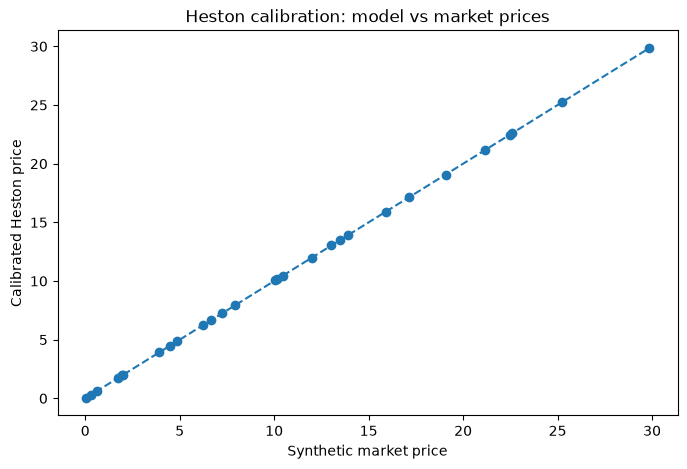

In [ ]:
# Scatter plot of reconstructed price and market price
plt.figure(figsize=(8, 5))
plt.scatter(market_prices, calibrated_prices)
plt.plot([market_prices.min(), market_prices.max()], [market_prices.min(), market_prices.max()], linestyle="--")
plt.xlabel("Synthetic market price [a.u.]")
plt.ylabel("Calibrated Heston price [a.u.]")
plt.title("Heston calibration: model vs market prices")
plt.show()

### Adding noise to simulation

In [ ]:
market_data_noise = []

rng = np.random.default_rng(5)


for T in maturities:
    for K in strikes:
        true_price = price_heston_call(S0=S0, K=K, v0=true_param["v0"], rate=rate, dividend_yield=dividend_yield,
            kappa=true_param["kappa"], theta=true_param["theta"], ksi=true_param["ksi"], rho=true_param["rho"], T=T)

        noise = rng.normal(0.0, noise_std)
        market_data_noise.append({"strike": K, "maturity": T, "true_price": true_price, "price": true_price + noise})



In [22]:
# Calibration

initial_guess = np.array([0.08,  # v0
                        1.0,  # kappa
                        0.08,  # theta
                        0.3,   # ksi
                        -0.3  # rho
                        ])

result_noise = calibrate_heston(initial_guess=initial_guess, market_data=market_data_noise, S0=S0, rate=rate, dividend_yield=dividend_yield)
print('Result', result_noise.x)
estimated_params_noise = result_noise.x

parameter_names = ["v0","kappa","theta","ksi","rho"]

true_values = np.array([true_param["v0"],true_param["kappa"],true_param["theta"],true_param["ksi"],true_param["rho"]])

for name, true_value, estimated_value in zip(parameter_names, true_values, estimated_params_noise):
    print(f"{name}: " f"true = {true_value:.6f}, " f"estimated = {estimated_value:.6f}")

Result [ 0.03958027  1.73027317  0.04064707  0.49709981 -0.67182289]
v0: true = 0.040000, estimated = 0.039580
kappa: true = 2.000000, estimated = 1.730273
theta: true = 0.040000, estimated = 0.040647
ksi: true = 0.500000, estimated = 0.497100
rho: true = -0.700000, estimated = -0.671823


RMSE: 0.08579613973670955
Max error: 0.18016697152120997


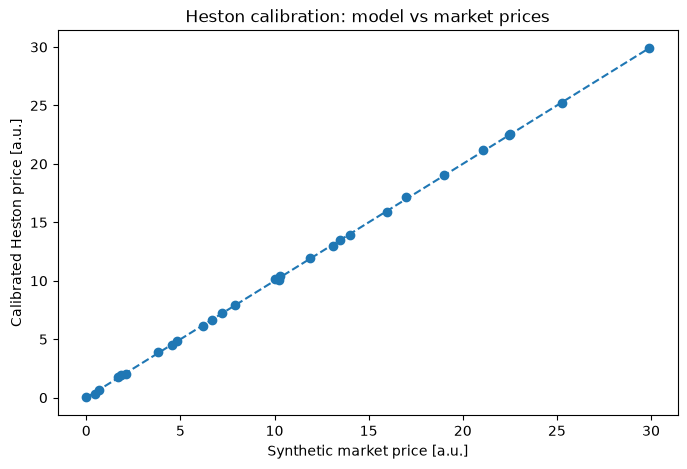

In [ ]:
# Prices from reconstructed model
calibrated_prices = []

for row in market_data_noise:
    price = price_heston_call(S0=S0, K=row["strike"], v0=estimated_params_noise[0], rate=rate, dividend_yield=dividend_yield,
        kappa=estimated_params_noise[1], theta=estimated_params_noise[2], ksi=estimated_params_noise[3], rho=estimated_params_noise[4], T=row["maturity"])
    calibrated_prices.append(price)

market_prices_noise = np.array([row["price"] for row in market_data_noise])

calibrated_prices = np.array(calibrated_prices)
errors = calibrated_prices - market_prices_noise

print("RMSE:", np.sqrt(np.mean(errors**2)))
print("Max error:", np.max(np.abs(errors)))

# Scatter plot of reconstructed price and market price
plt.figure(figsize=(8, 5))
plt.scatter(market_prices_noise, calibrated_prices)
plt.plot([market_prices_noise.min(), market_prices_noise.max()], [market_prices_noise.min(), market_prices_noise.max()], linestyle="--")
plt.xlabel("Synthetic market price [a.u.]")
plt.ylabel("Calibrated Heston price [a.u.]")
plt.title("Heston calibration: model vs market prices")
plt.show()

## 2) Fisher information

In [ ]:
# Jacobian for all options in the market as set by market data
# dimensions: number of market options x number of Heston parameters
# each column all market options sensitivity to one heston parameter
# each row one market option sensitivity to all heston parameters
jacobian = np.array([price_sensitivity(params=params, K=row["strike"], T=row["maturity"], S0=S0, rate=rate, dividend_yield=dividend_yield) for row in market_data_noise])

print(jacobian.shape) # number of market options x number of Heston parameters

(28, 5)


In [26]:
# Fisher information calculation as I = J.T @ W @ J
# noise applied to market data in model
noise_std_fisher = noise_std

# assumption: independent noise on market options
W = np.eye(len(market_data_noise)) / noise_std_fisher**2

fisher_information = jacobian.T @ W @ jacobian
print(fisher_information) # should be 5x5 matrix as 5 parameters in Heston model
# on-diagonal: individual information per parameter
# off-diagonal: how similarly do changes in one parameter and changes in another 
              # parameter affect option prices, accounting for measurement noise

[[ 2.58697140e+06  1.22598797e+04  3.44692245e+06 -9.84829456e+04
   2.57198860e+04]
 [ 1.22598797e+04  1.44725393e+02  2.75583832e+04 -9.37717056e+02
   4.04993597e+02]
 [ 3.44692245e+06  2.75583832e+04  7.45305901e+06 -1.80636069e+05
   4.64933976e+04]
 [-9.84829456e+04 -9.37717056e+02 -1.80636069e+05  6.66035233e+03
  -2.91682673e+03]
 [ 2.57198860e+04  4.04993597e+02  4.64933976e+04 -2.91682673e+03
   2.04756951e+03]]


In [27]:
# Analysis of Fisher information matrix

eigenvalues = np.linalg.eigvalsh(fisher_information)

print('Eig values', eigenvalues)
condition_number = (eigenvalues.max()/eigenvalues.min())

print("Condition number", condition_number)

Eig values [5.15953508e+00 1.65772791e+02 3.66711769e+03 8.00925030e+05
 9.24411998e+06]
Condition number 1791657.5509395825


In [28]:
# Cramer Rao lower bound calculation for standard errors lower bound on parameters
covariance_lower_bound = np.linalg.inv(fisher_information)
parameter_std_lower_bound = np.sqrt(np.diag(covariance_lower_bound))

for name, std in zip(parameter_names, parameter_std_lower_bound):
    print(f"{name}: {std:.6f}")

v0: 0.001579
kappa: 0.436664
theta: 0.001182
ksi: 0.077389
rho: 0.058768


### 3) Fisher information per market option

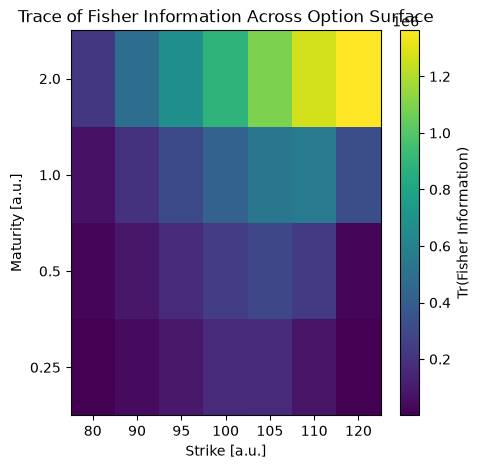

In [36]:
from calibration.fisher import price_sensitivity

params = np.array([true_param["v0"], true_param["kappa"], true_param["theta"], true_param["ksi"], true_param["rho"]])

fisher_matrices = {}

for T in maturities:
    for K in strikes:
        jacobian = price_sensitivity(params=params, K=K, T=T, S0=S0, rate=rate, dividend_yield=dividend_yield) 
        noise_std_fisher = noise_std
        W = np.eye(1) / noise_std_fisher**2
        # print(jacobian.shape)

        jacobian = jacobian.reshape(1, -1)

        fisher_matrices[(T, K)] = (jacobian.T @ jacobian/noise_std_fisher**2)

trace_fisher = {(T, K): np.trace(I) for (T, K), I in fisher_matrices.items()}

trace_matrix = np.array([[trace_fisher[(T, K)] for K in strikes] for T in maturities])

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(trace_matrix, aspect="auto", origin="lower")
ax.set_xticks(np.arange(len(strikes)))
ax.set_xticklabels(strikes)
ax.set_yticks(np.arange(len(maturities)))
ax.set_yticklabels(maturities)
ax.set_xlabel("Strike [a.u.]")
ax.set_ylabel("Maturity [a.u.]")
ax.set_title("Trace of Fisher Information Across Option Surface")
fig.colorbar(im, ax=ax, label="Tr(Fisher Information)")
plt.show()

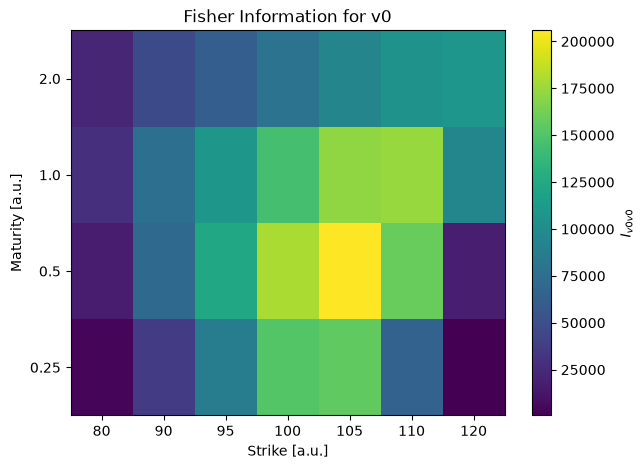

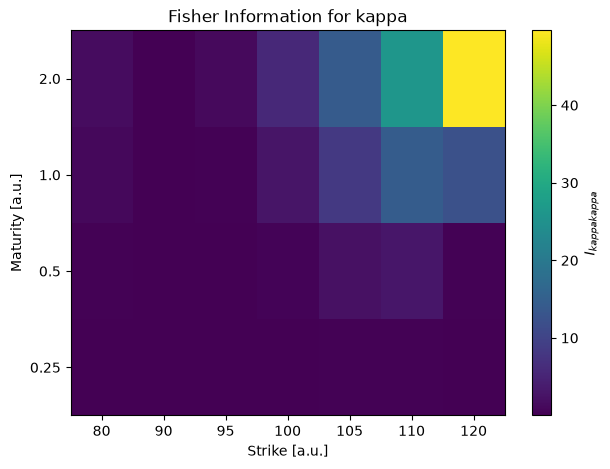

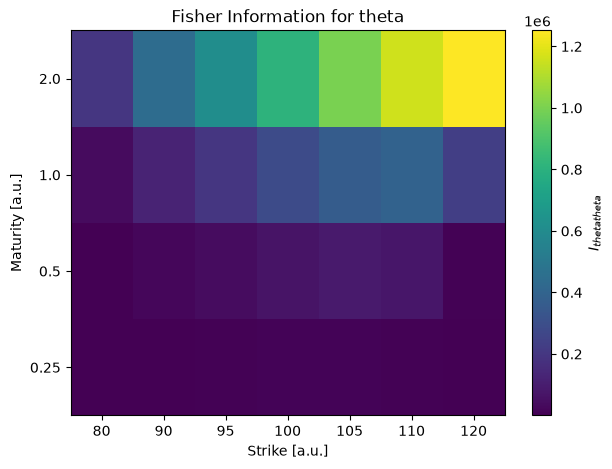

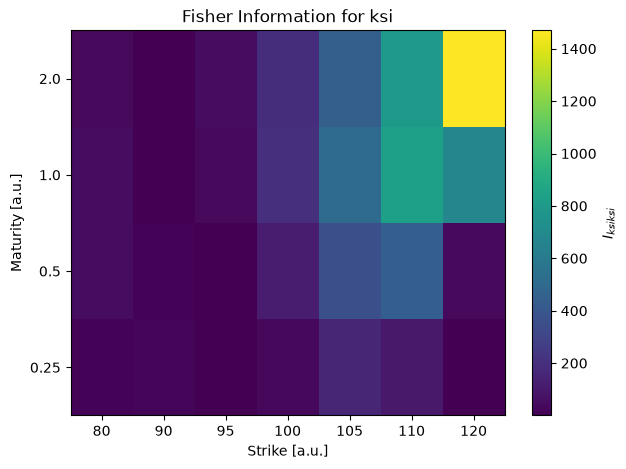

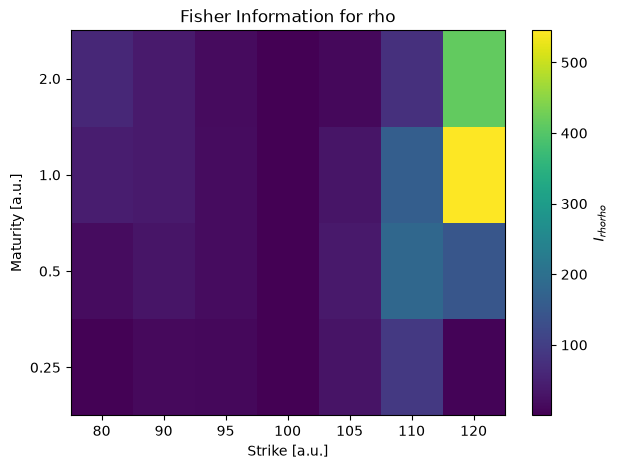

In [38]:
parameter_names = ["v0", "kappa", "theta", "ksi", "rho"]

for j, parameter in enumerate(parameter_names):

    parameter_matrix = np.array([[fisher_matrices[(T, K)][j, j] for K in strikes] for T in maturities])
    fig, ax = plt.subplots(figsize=(7, 5))
    im = ax.imshow(parameter_matrix, aspect="auto", origin="lower")
    ax.set_xticks(np.arange(len(strikes)))
    ax.set_xticklabels(strikes)
    ax.set_yticks(np.arange(len(maturities)))
    ax.set_yticklabels(maturities)
    ax.set_xlabel("Strike [a.u.]")
    ax.set_ylabel("Maturity [a.u.]")
    ax.set_title(f"Fisher Information for {parameter}")

    fig.colorbar(im, ax=ax, label=fr"$I_{{{parameter}{parameter}}}$")
    plt.show()

The different parameters show different optimal points of highest fisher information indicating different points in the maturity-strike surface might serve to obtain optimal information for different parameters

### 4) Selection of options based on D-optimality criterion

[(np.float64(2.0), np.int64(120)), (np.float64(2.0), np.int64(90)), (np.float64(0.5), np.int64(105)), (np.float64(1.0), np.int64(120)), (np.float64(0.25), np.int64(95)), (np.float64(2.0), np.int64(80)), (np.float64(0.25), np.int64(90)), (np.float64(0.5), np.int64(120)), (np.float64(2.0), np.int64(110)), (np.float64(0.5), np.int64(110))]


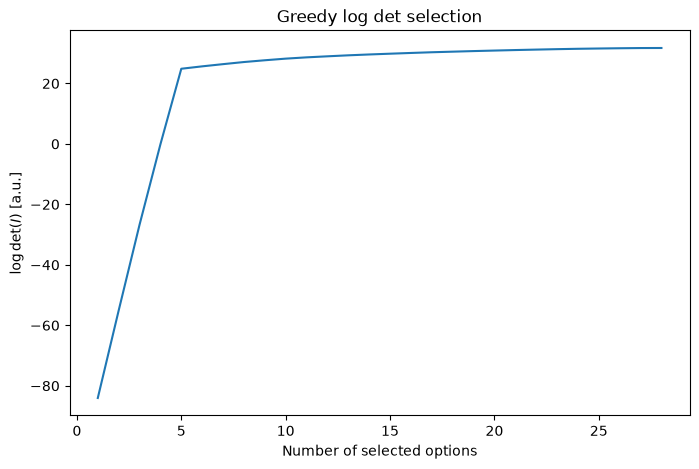

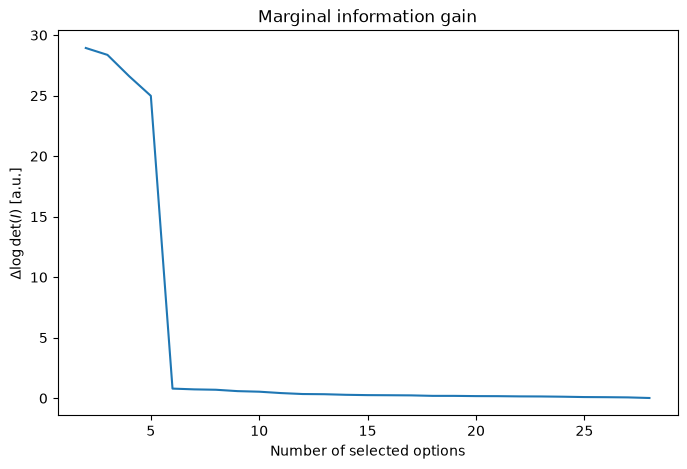

In [57]:
# Selection of most informative option points on strike-maturity surface based on maximising log(det(I)) for 
# sequential selection of option points

# Scale Fisher matrices based on scale of Heston parameters to remove dependence on parameter scale before selecting based on log det
scales = np.array([true_param["v0"],true_param["kappa"], true_param["theta"], true_param["ksi"], 1.0])
scaled_fisher_matrices = {option: scale_fisher_matrix(I, scales) for option, I in fisher_matrices.items()}

selected, logdet_history = greedy_d_optimal_selection(scaled_fisher_matrices)
print(selected[:10])

n_selected = np.arange(1, len(logdet_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_selected, logdet_history)
plt.xlabel("Number of selected options")
plt.ylabel(r"$\log \det(I)$ [a.u.]")
plt.title("Greedy log det selection")
plt.show()

marginal_gain = np.diff(logdet_history)

plt.figure(figsize=(8, 5))
plt.plot(np.arange(2, len(logdet_history) + 1), marginal_gain)
plt.xlabel("Number of selected options")
plt.ylabel(r"$\Delta \log \det(I)$ [a.u.]")
plt.title("Marginal information gain")
plt.show()